# Beyond: a portfolio engine reconciled to its analytic anchors, and an honest size and power for the correlation estimate

**Question:** Does the portfolio engine return the numbers that exist outside it (an integral, the IRB formula, closed forms, a published test vector), and how often does its correlation test err when the truth is known?

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebooks 01 to 07 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- state the claim this notebook demonstrates, BS-6, as far as its evidence goes, and say what it does not claim;
- check the portfolio engine against four anchors that do not come from the engine itself: the integral of the large-portfolio density, the IRB capital formula written with SciPy, the closed-form probability and variance of CreditRisk+, and the published granularity test vector;
- reproduce a committed Monte Carlo rung to eight digits with the released engine, and say why that is a stronger statement than agreeing within a standard error;
- see the engine's estimator of the correlation recovered against a known truth, with its bias, error and coverage, on the committed simulator grid;
- spot-check one cell of that grid live, and read the measured size and power of the correlation test with their errors;
- say what the absence claim rests on, with its date, and where it stops.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import integrate, stats

# The notebook sits three folders below the repository root
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))


# Names of the validation lights
LIGHTS = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Four committed files of case C10 (owner: this repository; the loss rates behind the fits come from the Federal Reserve's table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, public domain, licence class `mirror-allowed`):

- `commercial-industrial.json`: the illustrative book of 1,120 names (constructed, never a bank's), the committed ladder with its seeds and chunk sizes, and the CreditRisk+ rung;
- `credit-cards.json`: the fit and the IRB reference of the credit-card book, used for the IRB anchor because the retail revolving class has a fixed correlation and no maturity adjustment;
- `grid-22.json` and `grid-40.json`: the simulator grid, `truth_status` `synthetic-known-truth`: yearly default fractions of a large portfolio drawn with a known PD of 2% and twelve known correlations, 400 replications per cell, series of 22 and 40 years.

The next cell loads them and prints the truth status of each, which says whether a comparison is against real outcomes or against a known truth.

In [2]:
# Load the four artifacts and print the truth status of each
read = lambda name: json.loads((ROOT / "data" / "derived" / "C10" / f"{name}.json").read_text(encoding="utf-8"))
ci, cards, grid22, grid40 = read("commercial-industrial"), read("credit-cards"), read("grid-22"), read("grid-40")
TRUTH = {"real-outcomes": "real outcomes", "synthetic-known-truth": "synthetic, known truth"}

for name, doc in (("commercial-industrial", ci), ("credit-cards", cards), ("grid-22", grid22), ("grid-40", grid40)):
    print(f"{name:22s} {TRUTH[doc['provenance']['truth_status']]}")

print("baked by riskvalidation", {d["provenance"]["riskvalidation_version"] for d in (ci, cards, grid22, grid40)})
out = ci["outputs"]
book = out["portfolio"]
pd_hat = out["fit"]["maximum_likelihood"]["pd"]["estimate"]
rho_hat = out["fit"]["maximum_likelihood"]["rho"]["estimate"]
rungs = {r["id"]: r for r in out["rungs"]}
print("book:", book["n_names"], "names")

commercial-industrial  real outcomes
credit-cards           real outcomes
grid-22                synthetic, known truth
grid-40                synthetic, known truth
baked by riskvalidation {'1.0.1'}
book: 1120 names


## Method

An engine with no open reference to compare against can only be held to things that exist outside it. This notebook uses three kinds, each demonstrated below:

1. **Analytic anchors**: closed forms and published values that the engine's own code does not compute. Steps 1 to 4.
2. **Its own committed output, regenerated**: a Monte Carlo rung that the released engine must reproduce exactly, because the generator is seeded. Step 5.
3. **Known truth**: a simulator that draws data with a known correlation, so an estimator's error is measured instead of assumed. Steps 6 and 7.

### Step 1: the large-portfolio distribution against the integral of its density

The distribution function and the density of notebook 01 are two engine functions. If they are right, the integral of the density from 0 to $x$ is the distribution function at $x$. The integral is computed by SciPy's adaptive quadrature, which uses neither of the closed forms.

In [3]:
# Integrate the engine density with SciPy quadrature and compare it with the engine distribution function
from riskvalidation.engines.vasicek import lhp_cdf, lhp_pdf

points = np.array([0.002, 0.005, 0.01, 0.02, 0.035, 0.05, 0.07])
density = lambda t: float(lhp_pdf(t, pd_hat, rho_hat))
areas = np.array([integrate.quad(density, 0.0, x, limit=200)[0] for x in points])
cdf = np.array([float(lhp_cdf(x, pd_hat, rho_hat)) for x in points])

print(f"{'x':>7s} {'integral of the density':>34s} {'distribution function':>30s} {'difference':>12s}")
for x, area, value in zip(points, areas, cdf):
    print(f"{x:7.3f} {area:34.12f} {value:30.12f} {area - value:12.1e}")

      x            integral of the density          distribution function   difference
  0.002                     0.046571310489                 0.046571310492     -2.8e-12
  0.005                     0.301630749213                 0.301630749213     -2.2e-13
  0.010                     0.668927037945                 0.668927037945     -2.2e-13
  0.020                     0.930865477961                 0.930865477961     -2.2e-13
  0.035                     0.992015590416                 0.992015590420     -4.3e-12
  0.050                     0.998856665187                 0.998856665187     -7.9e-13
  0.070                     0.999891570323                 0.999891570328     -4.3e-12


The next cell draws the distribution function with the integrals as markers, and the size of their difference on a logarithmic axis.

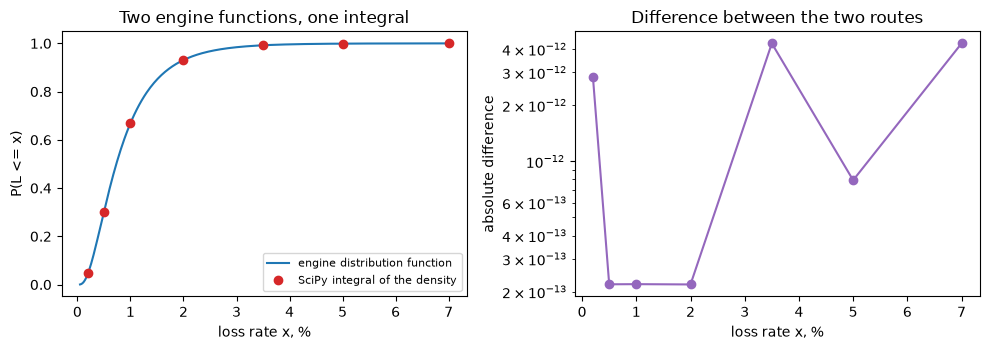

In [4]:
# Draw the distribution function against the integral of the density, and their difference
grid = np.linspace(0.0005, 0.07, 300)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
curve = [float(lhp_cdf(x, pd_hat, rho_hat)) for x in grid]
left.plot(100 * grid, curve, color="tab:blue", label="engine distribution function")
left.plot(100 * points, areas, "o", color="tab:red", label="SciPy integral of the density")
left.set_xlabel("loss rate x, %")
left.set_ylabel("P(L <= x)")
left.set_title("Two engine functions, one integral")
left.legend(fontsize=8)
right.semilogy(100 * points, np.abs(areas - cdf), "o-", color="tab:purple")
right.set_xlabel("loss rate x, %")
right.set_ylabel("absolute difference")
right.set_title("Difference between the two routes")
fig.tight_layout()
plt.show()

On the left the red markers, computed by integrating the density with SciPy's adaptive quadrature, sit exactly on the blue distribution function that the engine computes in closed form. On the right the difference is below 1e-12 at every point, which is the accuracy of the quadrature, not of the engine. The check is an anchor because the integral uses neither closed form: if the density had a wrong constant or the distribution function a sign error, the markers would leave the curve. It is also a necessary condition only, since a pair of functions that are wrong in a compatible way would still pass, and it says nothing about whether the fitted PD and correlation describe any real portfolio.

### Step 2: the IRB capital against the formula written with SciPy

The Basel IRB capital requirement for an exposure of a given PD and LGD is the large-portfolio 99.9% capital at the regulatory correlation $R$ (BCBS, 2005, https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf; Basel Framework CRE31, https://www.bis.org/basel_framework/chapter/CRE/31.htm). For a retail revolving exposure, which has a fixed correlation $R=0.04$ and no maturity adjustment, it is

$$K=\mathrm{LGD}\left[\Phi\!\left(\frac{\Phi^{-1}(\mathrm{PD})+\sqrt{R}\,\Phi^{-1}(0.999)}{\sqrt{1-R}}\right)-\mathrm{PD}\right]$$

The next cell evaluates it with SciPy's normal distribution at the fitted PD of the credit-card book, and compares it with two engine answers: the IRB module's `capital_requirement` and the large-portfolio capital `lhp_measures` at the same correlation.

In [5]:
# Evaluate the IRB formula with SciPy and compare it with the IRB module and the large-portfolio capital
from riskvalidation.portfolio.portfolio import lhp_measures
from riskvalidation.regulatory.irb import capital_requirement

c_out = cards["outputs"]
pd_cards = c_out["fit"]["maximum_likelihood"]["pd"]["estimate"]
reference = c_out["irb_reference"]
lgd, corr = 0.45, reference["irb_correlation"]

threshold = (stats.norm.ppf(pd_cards) + math.sqrt(corr) * stats.norm.ppf(0.999)) / math.sqrt(1 - corr)
k_scipy = lgd * (stats.norm.cdf(threshold) - pd_cards)
k_module = float(capital_requirement(reference["asset_class"], pd_cards, lgd, regime="basel3").k)
k_lhp = lhp_measures(1.0, lgd, pd_cards, corr, (0.999,))[0].ec
print("asset class:", reference["asset_class"], "| PD:", round(pd_cards, 6), "| R:", corr, "| LGD:", lgd)
print(f"K SciPy formula  {k_scipy:.12f}")
print(f"K IRB module        {k_module:.12f}   difference {k_module - k_scipy:.1e}")
print(f"K large portfolio    {k_lhp:.12f}   difference {k_lhp - k_scipy:.1e}")

asset class: qrre | PD: 0.042281 | R: 0.04 | LGD: 0.45
K SciPy formula  0.039169914547
K IRB module        0.039169914547   difference 0.0e+00
K large portfolio    0.039169914547   difference 0.0e+00


### Step 3: CreditRisk+ against its closed forms

The CreditRisk+ recursion of notebook 04 computes the whole distribution of the loss in units. Two properties of the model are known in closed form from its generating function, so they anchor the recursion without a second implementation of it. With one sector, no idiosyncratic weight and Gamma variance $\sigma^2$, the probability of no loss is $P(X=0)=(1+\sigma^2\mu)^{-1/\sigma^2}$ with $\mu=\sum_ip_i$ (Haaf, Reiss and Schoenmakers, 2004, https://doi.org/10.21314/jor.2004.097), and, conditioning on the Gamma factor $S$ (mean 1, variance $\sigma^2$), the mean and variance of the loss in units are

$$E[X]=\sum_i\nu_ip_i,\qquad \mathrm{Var}(X)=\sum_i\nu_i^2p_i+\sigma^2\Big(\sum_i\nu_ip_i\Big)^2$$

(the first term is the Poisson variance given $S$, the second the variance of the conditional mean; this is a derivation from the model, not a quoted formula). The next cell runs the stable recursion on the commercial book and compares the mean and variance of its probability function with these.

In [6]:
# Run the stable recursion and compare P(X = 0), the mean and the variance with the closed forms
from riskvalidation.portfolio import creditrisk_plus as cr

crp = rungs["c4-creditrisk-plus"]
sigma2 = next(p["value"] for p in crp["parameters"] if p["name"] == "sigma2")
loss_unit = next(p["value"] for p in crp["parameters"] if p["name"] == "loss_unit")
n_max = int(next(d["value"] for d in crp["diagnostics"] if d["name"] == "n_max"))
ead = np.concatenate([np.full(g["n_names"], g["ead_each"]) for g in book["groups"]])
pd_names = np.concatenate([np.full(g["n_names"], g["pd"]) for g in book["groups"]])
units = np.rint(ead * book["lgd_mean"] / loss_unit).astype(int)
inp = cr.CreditRiskPlusInput(
    nu=units, pd=pd_names, w0=np.zeros(ead.size), weights=np.ones((ead.size, 1)),
    sigma2=np.array([sigma2]), loss_unit=loss_unit, currency=book["currency"])
pmf = cr.pmf_stable(inp, n_max)

n = np.arange(pmf.size)
mean_pmf = float((n * pmf).sum())
var_pmf = float(((n - mean_pmf) ** 2 * pmf).sum())
mu = float(pd_names.sum())
mean_closed = float((units * pd_names).sum())
var_closed = float((units ** 2 * pd_names).sum() + sigma2 * mean_closed ** 2)
print("mass left out of the grid:", f"{1 - pmf.sum():.1e}")
print(f"P(X = 0)  recursion {pmf[0]:.12e} | closed form {(1 + sigma2 * mu) ** (-1 / sigma2):.12e}")
print(f"mean      recursion {mean_pmf:.6f} | closed form {mean_closed:.6f}")
print(f"variance   recursion {var_pmf:.4f} | closed form {var_closed:.4f}")
print("relative gap of the variance:", f"{abs(var_pmf - var_closed) / var_closed:.1e}")

mass left out of the grid: 2.7e-13
P(X = 0)  recursion 1.546187529854e-02 | closed form 1.546187529854e-02
mean      recursion 409.720505 | closed form 409.720505
variance   recursion 208626.6484 | closed form 208626.6484
relative gap of the variance: 5.5e-11


### Step 4: the granularity test vector of the paper

Gordy and Lutkebohmert (2013, https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf) print one number that anyone implementing their adjustment can reproduce: $\delta=4.83$ at $\xi=0.25$ and $q=0.999$. The research read it directly from the paper. The engine computes $\delta=(\alpha_q-1)(\xi+(1-\xi)/\alpha_q)$ from the quantile of a Gamma distribution. The second identity is the one the paper's formula implies: for $n$ identical names the adjustment is proportional to $1/n$, so $\mathrm{GA}\times n$ does not move. The next cell reproduces the vector and checks the identity.

In [7]:
# Compute the paper test vector and check that GA times n is constant for identical names
from riskvalidation.portfolio import granularity as gr

gran = out["granularity"]
delta = gr.delta(gran["xi"], 0.999)
PUBLISHED_DELTA = 4.83
print("delta (xi = 0.25, q = 0.999):", round(delta, 4), "| published:", PUBLISHED_DELTA)
print("the engine agrees to the printed digits:", round(delta, 2) == PUBLISHED_DELTA)

k_names = float(capital_requirement("corporate", pd_hat, 0.45, regime="basel3", maturity=2.5).k)
products = []
for n_names in (10, 100, 1000, 10_000):
    ones = np.ones(n_names)
    result = gr.granularity_adjustment(
        ones / n_names, k_names * ones, pd_hat * ones, 0.45 * ones, gran["gamma"], gran["xi"], 0.999)
    products.append(result.ga * n_names)
    print(f"n = {n_names:6d} | GA = {result.ga:.8f} | GA x n = {result.ga * n_names:.8f}")
print("largest relative spread of GA x n:", f"{(max(products) - min(products)) / max(products):.1e}")

delta (xi = 0.25, q = 0.999): 4.8336 | published: 4.83
the engine agrees to the printed digits: True
n =     10 | GA = 0.12076364 | GA x n = 1.20763644
n =    100 | GA = 0.01207636 | GA x n = 1.20763644
n =   1000 | GA = 0.00120764 | GA x n = 1.20763644
n =  10000 | GA = 0.00012076 | GA x n = 1.20763644
largest relative spread of GA x n: 7.7e-15


## State of the art

The practice this notebook goes beyond is the one the research recorded for portfolio credit engines. The formulas are in the literature and are what an engine is checked against: the large-portfolio limit and the IRB formula (Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8; BCBS, 2005), the CreditRisk+ generating function and its stable recursion (Haaf, Reiss and Schoenmakers, 2004), and the granularity adjustment with its test vector (Gordy and Lutkebohmert, 2013). The research (persisted dossier 04, section H.8) records the implementations available on 2026-10-04: the CRAN packages CreditMetrics and crp.CSFP are archived, GCPM 1.2.2 (CRAN, 2016) is old and GPL-2, the Open Risk portfolioAnalytics repository is GPL-2.0, and small educational repositories exist (one in Julia, MIT). It concluded that **no maintained, permissively licensed Python implementation of CreditMetrics or CreditRisk+ was found**, and that an engine should therefore be validated against analytic anchors rather than against an unmaintained library. That is a statement of practice and of its limits: the dossier searched CRAN and GitHub for these two model families on that date, and nothing here widens the search. For the validation of an economic capital model the dossier (05, section G.5) prescribes checks that the allocation sums to the total and sensitivity checks, and notes that a Binomial test on a few years has little power.

## Beyond the state of the art

**Claim BS-6, for the portfolio engine.** Contraste ships a copula and CreditRisk+ portfolio engine (and a catalogue of five portfolio validation tests) under a permissive licence, and holds it to anchors that exist outside it. This is an absence claim paired with evidence: the absence is the dossier's, dated 2026-10-04 and bounded as in the section above; the evidence is what the steps of this notebook show and a reader can open:

- the committed rows and the closed forms of Steps 1 to 4, reproduced here;
- the committed Gaussian copula rung, regenerated to eight digits in Step 5;
- the size, power and coverage rows of the simulator grid, `data/derived/C10/grid-22.json` and `grid-40.json`, read in Steps 6 and 7.

**What is not claimed.** The claim is not that the engine equals a reference implementation, because the research found none to compare with. It is not that the engine is free of defects: its anchors are necessary conditions. It does not extend the absence beyond CRAN and GitHub on 2026-10-04 (the claim in the SDD names the other two components, the ECB tests and the IRRBB engine, which their own topics demonstrate). The Student t importance sampler is a gap the engine records and does not hide. And the measured size and power of the correlation estimator below is evidence about one estimator on one generator, not the general claim that every test of the product has its size and power measured.

Step 5 regenerates the committed Gaussian copula rung with the released engine. The ladder was baked with engine 0.7.0 and the installed engine is 0.8.1, and the rung was drawn with a seeded generator at a fixed chunk size, so a faithful engine must return the same sample. The run uses all 1,000,000 scenarios of the committed rung, because equality to eight digits is the point (it takes about half a minute and is the only cell of the topic at the committed size). The next cell reruns it and compares VaR, ES and their standard errors, digit by digit, with the committed values.

In [8]:
# Regenerate the Gaussian copula rung of the case with the released engine and compare it digit by digit
from riskvalidation.portfolio import copula
from riskvalidation.portfolio import portfolio as pf

committed = rungs["c2-gaussian-1f"]
sim = committed["simulation"]
one = pf.portfolio_from_groups(book["groups"], book["currency"], book["lgd_gamma"], one_factor=True)
sample = copula.simulate_gaussian(one, sim["n_scenarios"], sim["seed"], sim["chunk_size"])
rerun = pf.measures_from_sample(sample.losses, (0.99, 0.999), pf.expected_loss(one))

relative = []
for m, c in zip(rerun, committed["measures"]):
    pairs = ((m.var, c["var"]), (m.es, c["es"]), (m.var_se, c["var_se"]), (m.es_se, c["es_se"]))
    relative.extend(abs(mine - theirs) / theirs for mine, theirs in pairs)
print("scenarios:", sim["n_scenarios"], "| seed:", sim["seed"], "| chunk:", sim["chunk_size"])
print("largest relative difference over the eight values:", f"{max(relative):.1e}")

scenarios: 1000000 | seed: 4001 | chunk: 16741
largest relative difference over the eight values: 2.9e-09


### Step 6: the correlation estimator against a known truth

The simulator grid is the engine's own estimator held against a truth that the data cannot hide. Each cell draws 400 series of yearly default fractions with a known correlation, fits both estimators of notebook 02, and records the mean estimate, the **bias** (the mean estimate minus the known value), the root-mean-square error and the **coverage** of the nominal 95% interval, the share of replications whose interval contains the true correlation. A well-calibrated interval has coverage near 0.95. The next cell draws the bias, the root-mean-square error and the coverage of both estimators against the known correlation, for the 22-year and the 40-year grid, from the committed `cells`.

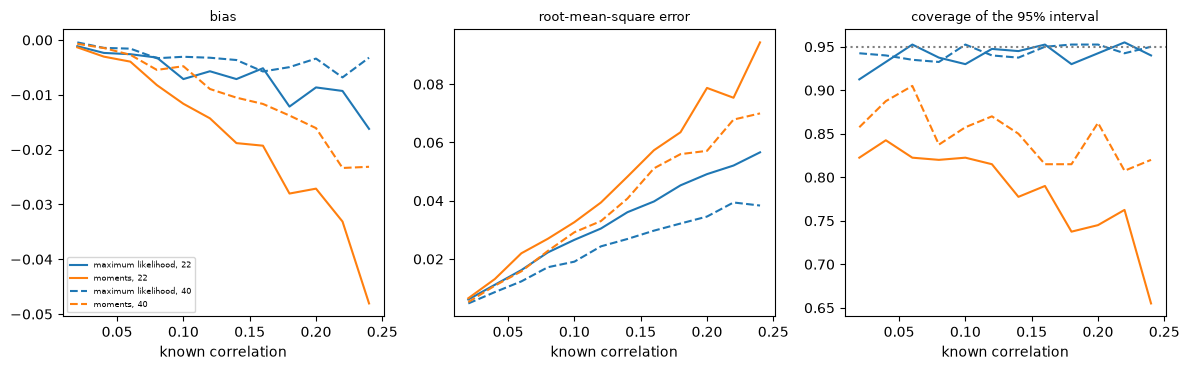

In [9]:
# Draw the bias, the error and the coverage of both estimators against the known correlation
estimators = (
    ("maximum-likelihood", "tab:blue", "maximum likelihood"),
    ("moments", "tab:orange", "moments"),
)
measures = (
    ("bias", "bias"),
    ("rmse", "root-mean-square error"),
    ("coverage", "coverage of the 95% interval"),
)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for years, grid_k, style in ((22, grid22, "-"), (40, grid40, "--")):
    cells = grid_k["outputs"]["cells"]
    rho_known = np.array([c["known_rho"] for c in cells])
    for name, color, label in estimators:
        picked = [next(e for e in c["estimators"] if e["estimator"] == name) for c in cells]
        for ax, (field, _) in zip(axes, measures):
            ax.plot(rho_known, [e[field] for e in picked], style, color=color, label=f"{label}, {years}")
for ax, (_, title) in zip(axes, measures):
    ax.set_xlabel("known correlation")
    ax.set_title(title, fontsize=9)
axes[2].axhline(0.95, color="gray", linestyle=":")
axes[0].legend(fontsize=6)
fig.tight_layout()
plt.show()

Left, the bias: the maximum-likelihood estimator (blue) stays near zero and turns slightly negative as the true correlation grows, while the moments estimator (orange) falls much further below the truth, at 22 years as at 40. Centre, the error: it grows with the correlation for both estimators and is consistently larger for moments, and the 40-year curves (dashed) sit under the 22-year ones. Right, the coverage of the nominal 95% interval: blue stays near the dotted 0.95 line, orange falls well below it, to roughly two thirds at the highest correlation. A validator reading these three panels learns not just that the estimator is biased but by how much, where it matters, and that the interval attached to the moments estimator is not trustworthy. The grid is synthetic with a known truth, so these are properties of the estimators on this generator.

In [10]:
# Print the bias and the coverage of both estimators at three known correlations
failed = sum(c["n_failed"] for g in (grid22, grid40) for c in g["outputs"]["cells"])
print("replications that failed to fit in both grids:", failed)
print(f"{'years':>6s} {'known rho':>12s} {'estimator':>20s} {'bias':>8s} {'coverage':>9s}")
for years, grid_k in ((22, grid22), (40, grid40)):
    for cell in grid_k["outputs"]["cells"]:
        if round(cell["known_rho"], 2) not in (0.02, 0.12, 0.24):
            continue
        for e in cell["estimators"]:
            print(f"{years:6d} {cell['known_rho']:12.2f} {e['estimator']:>20s} {e['bias']:8.4f} {e['coverage']:9.3f}")

replications that failed to fit in both grids: 0
 years    known rho            estimator     bias  coverage
    22         0.02   maximum-likelihood  -0.0011     0.912
    22         0.02              moments  -0.0013     0.823
    22         0.12   maximum-likelihood  -0.0057     0.948
    22         0.12              moments  -0.0143     0.815
    22         0.24   maximum-likelihood  -0.0162     0.940
    22         0.24              moments  -0.0481     0.655
    40         0.02   maximum-likelihood  -0.0004     0.943
    40         0.02              moments  -0.0007     0.858
    40         0.12   maximum-likelihood  -0.0032     0.940
    40         0.12              moments  -0.0089     0.870
    40         0.24   maximum-likelihood  -0.0032     0.950
    40         0.24              moments  -0.0231     0.820


### Step 7: a live spot check of one cell, and the size and power of the test

The committed grid took the pipeline hours to bake, so we do not rerun it. We spot-check one cell, the size cell, with a smaller number of replications drawn here from the model's definition: 22 years of $x_t=p(z_t)$ with $z_t\sim N(0,1)$, the true PD of the grid (2%) and the true correlation 0.12, then the engine's maximum-likelihood fit and profile interval of notebook 02. The test of H0: $\rho=0.12$ rejects when 0.12 is outside the interval, so the rejection rate at the true value is the size, and the share of intervals that contain 0.12 is the coverage. With 100 replications the Monte Carlo error is large, so the result is read with its Wilson interval (Wilson, 1927, https://doi.org/10.1080/01621459.1927.10502953) and put beside the committed rates of the 400-replication grid, whose rows come from the engine's `correlation_size_power`.

In [11]:
# Spot-check the size cell live with 100 replications
from riskvalidation.engines.vasicek import conditional_pd
from riskvalidation.portfolio.asrf_fit import fit_ml, profile_interval
from riskvalidation.validation.portfolio import correlation_size_power

generator = grid22["outputs"]["generator"]
true_rho, true_pd = 0.12, generator["known_pd"]
years_n, null_rho = generator["series_length_years"], generator["null_rho"]
rng = np.random.default_rng(20261021)
rejected, estimates = [], []
for _ in range(100):
    rates = np.asarray(conditional_pd(true_pd, true_rho, rng.standard_normal(years_n)))
    fitted = fit_ml(rates)
    low, high = profile_interval(rates, 0.95)["rho"]
    rejected.append(not (low <= null_rho <= high))
    estimates.append(fitted.rho)

flags = np.array(rejected)
live = correlation_size_power(flags, true_rho, null_rho, alpha=generator["alpha"], estimator="maximum-likelihood")
print("live, 100 replications: rejection rate (size)", round(live.metric, 3))
print("error", round(live.extras["se"], 3), "| Wilson", round(live.extras["ci_low"], 3), end=" ")
print("-", round(live.extras["ci_high"], 3))
print("mean estimate:", round(float(np.mean(estimates)), 4))
for years, grid_k in ((22, grid22), (40, grid40)):
    for row in grid_k["tests"]:
        if row["extras"]["role"] == "size":
            x = row["extras"]
            head = f"grid {years}, {x['estimator']:18s}: size {row['metric']:.4f}"
            print(head, f"| Wilson {x['ci_low']:.3f} - {x['ci_high']:.3f}")

live, 100 replications: rejection rate (size) 0.08
error 0.027 | Wilson 0.041 - 0.15
mean estimate: 0.1193
grid 22, maximum-likelihood: size 0.0525 | Wilson 0.035 - 0.079
grid 22, moments           : size 0.1850 | Wilson 0.150 - 0.226
grid 40, maximum-likelihood: size 0.0600 | Wilson 0.041 - 0.088
grid 40, moments           : size 0.1300 | Wilson 0.101 - 0.167


The last figure puts the committed size and power on one picture for the maximum-likelihood estimator: the rejection rate against the known correlation at 22 and at 40 years, with the Wilson interval of every rate, the nominal level and the 80% power gate. It is the answer, on this generator, to the question a validator asks of any test: how often does it reject when it should not, and how often does it fail to reject when it should.

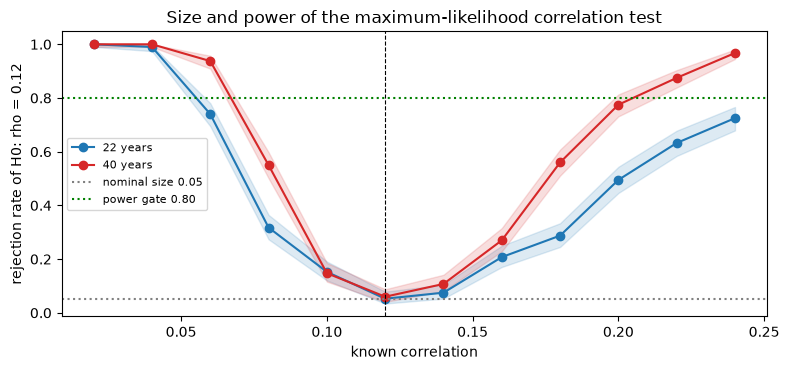

In [12]:
# Draw the size and power of the maximum-likelihood test at 22 and 40 years with their Wilson intervals
fig, ax = plt.subplots(figsize=(8, 3.8))
for (years, grid_k), color in zip(((22, grid22), (40, grid40)), ("tab:blue", "tab:red")):
    rows = [r for r in grid_k["tests"] if r["extras"]["estimator"] == "maximum-likelihood"]
    rho_known = np.array([r["extras"]["known_rho"] for r in rows])
    ax.plot(rho_known, [r["extras"]["rate"] for r in rows], marker="o", color=color, label=f"{years} years")
    band = ([r["extras"]["ci_low"] for r in rows], [r["extras"]["ci_high"] for r in rows])
    ax.fill_between(rho_known, band[0], band[1], color=color, alpha=0.15)
ax.axhline(0.05, color="gray", linestyle=":", label="nominal size 0.05")
ax.axhline(0.80, color="green", linestyle=":", label="power gate 0.80")
ax.axvline(0.12, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("known correlation")
ax.set_ylabel("rejection rate of H0: rho = 0.12")
ax.set_title("Size and power of the maximum-likelihood correlation test")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The blue curve, 22 years, is close to the nominal 5% at the null and then climbs slowly: it rejects a correlation of 0.10 only 15% of the time and one of 0.14 only 7.5%, so the test cannot tell neighbours of 0.12 from 0.12, and it never reaches the 80% gate above the null at this length (72.5% at 0.24). The red curve, 40 years, is higher on both sides and crosses the gate between 0.20 and 0.22. The bands are the Wilson intervals of 400 replications, and they show that the rates near the null are known to a few points only. This is the answer, on this generator, to the question a validator asks of any test: how often does it reject when it should not, and how often does it fail to reject when it should.

## Results

**Answer:** yes, the engine returns the numbers that exist outside it: the integral of its density equals its distribution function to within 4.3e-12, the IRB capital 0.039169914547 equals the formula written with SciPy (difference 0.0e+00), the CreditRisk+ probability of no loss, 1.546187529854e-02, and the variance, 208626.6484, match their closed forms (relative gap 5.5e-11), $\delta=4.8336$ matches the published 4.83, and the seeded copula rung is regenerated to a relative 2.9e-09; against a known truth its maximum-likelihood correlation test rejects a true correlation 5.25% of the time at 22 years against a nominal 5%, and its interval covers 0.948 at a correlation of 0.12 where the moments interval covers 0.815.

- **Step 1, the two engine functions agree through a third route.** The integral of the engine's density from 0 to $x$, computed by SciPy's quadrature, equals the engine's distribution function to 2.2e-13 at x = 0.005, 0.01 and 0.02, to 7.9e-13 at 0.05 and to at most 4.3e-12 at the other three points, which is the quadrature's own error. A mistake in either the density or the distribution function would show here.
- **Step 2, the IRB capital agrees with the formula to the last digit, and the reason limits the check.** For the credit-card book (qrre class, PD 0.042281, R = 0.04, LGD 0.45) the formula written with SciPy gives K = 0.039169914547, and the IRB module and the large-portfolio capital return the same value with a difference of 0.0e+00. The digits are identical because all of them call the same normal distribution function of SciPy: the check holds the formula and the wiring of the engine, not SciPy's normal distribution.
- **Step 3, CreditRisk+ matches its closed forms.** The recursion's probability of no loss, 1.546187529854e-02, equals $(1+\sigma^2\mu)^{-1/\sigma^2}$ to twelve digits. Its mean, 409.720505 loss units, equals $\sum\nu_ip_i$, and its variance, 208,626.6484, equals the closed form with a relative gap of 5.5e-11, with 2.7e-13 of probability mass left outside the grid. The variance involves every probability of the recursion, so it is a demanding check of the whole distribution, not of one entry.
- **Step 4, the published test vector holds, and the adjustment scales as theory says.** $\delta=4.8336$ at $\xi=0.25$ and $q=0.999$ equals the paper's printed 4.83 to the printed digits. For identical names GA times $n$ is 1.20763644 at 10, 100, 1,000 and 10,000 names, with a relative spread of 7.7e-15.
- **Step 5, the released engine regenerates a committed Monte Carlo rung to eight digits.** With the seed 4001, chunk size 16741 and one million scenarios of the case, the largest relative difference over the VaR, the expected shortfall and the two standard errors at 99% and 99.9% is 2.9e-09, the rounding of the committed file. The rung was baked with an earlier release of the engine, so this is reproducibility across two releases of a seeded stochastic method, a stronger statement than agreeing within one standard error: any change to the sampler, the chunking or the estimators would move the digits. It does not show that the sampler is right, only that it is the same.
- **Step 6, against a known truth the maximum-likelihood estimator is nearly unbiased and its interval is nearly calibrated.** At 22 years its bias is -0.0011 at a true correlation of 0.02, -0.0057 at 0.12 and -0.0162 at 0.24, about 5% to 7% low, and the coverage of its nominal 95% interval is 0.912, 0.948 and 0.940. The moments estimator is more biased (-0.0143 at 0.12 and -0.0481 at 0.24, 12% and 20% low) and covers only 0.823, 0.815 and 0.655. At 40 years the maximum-likelihood coverage is 0.943, 0.940 and 0.950, and the moments coverage 0.858, 0.870 and 0.820. No replication failed to fit in any cell of either grid. A validator reading an interval from the moments estimator should not read it as a 95% interval.
- **Step 7, the live spot check agrees with the committed grid, with the noise to be expected.** With 100 replications at the true correlation 0.12 the live rejection rate is 0.08 (error 0.027, Wilson interval 0.041 to 0.15) and the mean estimate 0.1193, against 0.0525 (Wilson 0.035 to 0.079) of the 400-replication grid. The grid gives the maximum-likelihood test a size of 0.0525 at 22 years and 0.0600 at 40, both green, and the moments test 0.1850 and 0.1300, both red.
- **The size and power figure.** The maximum-likelihood test at 22 years has little power near the null (0.15 at a true correlation of 0.10, 0.075 at 0.14) and never reaches the 80% gate above it; at 40 years it passes 80% between 0.20 and 0.22. This is the engine's own answer to how often its correlation test rejects when it should not and fails to when it should, with the Monte Carlo error of every rate drawn as its Wilson interval.

**What the evidence supports, and where it stops.** The portfolio engine's closed-form anchors hold, the seeded copula rung is regenerated to eight digits and the estimator is measured against known truth. Together these support the claim BS-6 for this engine: it exists, under a permissive licence, and it is held to anchors outside itself. They do not support a statement that no equivalent exists anywhere: the absence is the research's finding on CRAN and GitHub on 2026-10-04, and this notebook cannot widen it. They do not prove the engine free of defects, they do not cover the ECB tests or the IRRBB engine that the claim also names, and the Student t importance sampler is a recorded gap.

## Summary

- BS-6, for the portfolio engine: a copula and CreditRisk+ engine under a permissive licence, held to anchors that exist outside it, with the absence finding of the research (CRAN and GitHub, 2026-10-04) stated as bounded and not extended.
- Four anchors hold: the integral of the large-portfolio density, the IRB formula written with SciPy, the CreditRisk+ probability of no loss, mean and variance, and the published granularity vector 4.83 with its 1/n scaling.
- The one-million-scenario Gaussian copula rung of the case is regenerated by the released engine to a relative 2.9e-09 across two releases.
- Against a known truth, the maximum-likelihood correlation estimator has low bias and near-nominal coverage, the moments estimator does not, and the size and power of the test are measured with their errors.
- What it does not claim: equality with a reference engine, freedom from defects, an absence beyond the dated search, or the other two components of the claim.

**What to try next.** Rerun Step 7 with 400 replications and a different seed and compare the Wilson interval with the 22-year size of the grid. Then read the SDD section `Beyond the state of the art`, where the claim is stated with its evidence.

## References

- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Gordy, M. B. and Lutkebohmert, E. (2013), Granularity adjustment for regulatory capital assessment, International Journal of Central Banking 9(3):33-48. https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf
- Haaf, H., Reiss, O. and Schoenmakers, J. (2004), Numerically stable computation of CreditRisk+, Journal of Risk 6(4):1-10. https://doi.org/10.21314/jor.2004.097
- BCBS, Basel Framework, CRE31: IRB approach, risk weight functions for corporate, bank, sovereign and retail exposures. https://www.bis.org/basel_framework/chapter/CRE/31.htm
- Wilson, E. B. (1927), Probable inference, the law of succession, and statistical inference, Journal of the American Statistical Association 22(158):209-212. https://doi.org/10.1080/01621459.1927.10502953
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- BCBS (2005), An Explanatory Note on the Basel II IRB Risk Weight Functions, https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf.
- Persisted research dossier 04 of this product (credit-risk models, state of the art), section H.8 (open implementations, searched 2026-10-04) and section H.5; dossier 05, section G.5 (validation tests of an economic capital model).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.